# A02 时间与预算有限，应完成哪些任务？

给定10项任务的预算、工时和教学价值评分，选择一组任务。先理解单预算背包，再把工时和依赖加入模型；输出是任务组合及其合法性证明式检查。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 明确输入与评分来源
用列表保存任务，字典字段让每个数字有名字。价值是本例假设评分。依赖 `(a,b)` 表示选择 a 必须同时选择 b。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

from ortools.sat.python import cp_model
tasks = [{"name": f"任务{i}", "cost": c, "hours": h, "value": v}
         for i, (c, h, v) in enumerate([(3,2,6),(4,3,7),(2,2,4),(5,4,10),(3,1,5),
                                       (6,5,11),(2,1,3),(4,2,8),(3,3,5),(5,3,9)])]
budget, hours = 16, 12
dependencies = [(3, 0), (5, 2), (7, 1)]
pd.DataFrame(tasks).to_csv(DATA_DIR / "候选任务.csv", index=False, encoding="utf-8-sig")
def valid_choice(chosen, jobs, money, time_limit, deps):
    if len(set(chosen)) != len(chosen): return False
    chosen = set(chosen)
    return (all(0 <= i < len(jobs) for i in chosen)
            and sum(jobs[i]["cost"] for i in chosen) <= money
            and sum(jobs[i]["hours"] for i in chosen) <= time_limit
            and all(a not in chosen or b in chosen for a, b in deps))
assert not valid_choice([0,0],tasks,100,100,dependencies)


## 2. 单预算背包：理解动态规划
`dp[b]` 表示预算最多 b 时的最高价值。预算倒序更新，防止同一个任务被重复选取。这一步暂时没有工时和依赖，不能把结果误用到完整任务。

In [3]:
def knapsack_value(jobs, cap):
    dp = [0] * (cap + 1)
    for job in jobs:
        for b in range(cap, job["cost"] - 1, -1):
            dp[b] = max(dp[b], dp[b-job["cost"]] + job["value"])
    return dp[-1]
unconstrained_value = knapsack_value(tasks, budget)
assert knapsack_value([{"cost": 2, "value": 3}], 4) == 3
print("只有预算时的价值上界：", unconstrained_value)


只有预算时的价值上界： 31


## 3. CP-SAT 同时处理多个约束
0/1变量表示是否选中。`x[a] <= x[b]` 精确表达依赖。检查器根据原始任务重新累加，不以求解器返回状态代替需求检查。

In [4]:
def optimize_tasks(jobs, money, time_limit, deps, require_all=False):
    model = cp_model.CpModel()
    x = [model.new_bool_var(f"pick_{i}") for i in range(len(jobs))]
    model.add(sum(j["cost"] * x[i] for i,j in enumerate(jobs)) <= money)
    model.add(sum(j["hours"] * x[i] for i,j in enumerate(jobs)) <= time_limit)
    for a,b in deps: model.add(x[a] <= x[b])
    if require_all:
        for variable in x: model.add(variable == 1)
    model.maximize(sum(j["value"] * x[i] for i,j in enumerate(jobs)))
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = 5
    solver.parameters.num_search_workers = 1
    status = solver.solve(model)
    chosen = ([i for i,var in enumerate(x) if solver.value(var)]
              if status in (cp_model.OPTIMAL, cp_model.FEASIBLE) else None)
    return solver.status_name(status), chosen
status, chosen = optimize_tasks(tasks, budget, hours, dependencies)
assert chosen is not None, f"未获得方案：{status}。UNKNOWN表示尚未找到或证明，不能解释为无解。"
assert valid_choice(chosen, tasks, budget, hours, dependencies)
# 10个任务只有1024种组合，用独立穷举核对小实例。
feasible = [list(i for i in range(len(tasks)) if bits[i])
            for bits in itertools.product([0,1], repeat=len(tasks))
            if valid_choice([i for i,b in enumerate(bits) if b], tasks, budget, hours, dependencies)]
value = sum(tasks[i]["value"] for i in chosen)
exact = max(sum(tasks[i]["value"] for i in c) for c in feasible)
assert value == exact and value <= unconstrained_value
impossible, _ = optimize_tasks(tasks, 0, 0, dependencies, require_all=True)
assert impossible == "INFEASIBLE"


## 4. 与简单选择法比较并保存计划
简单基线按价值/预算排序，在满足当前约束时才加入。它可能错过需要一起选择的依赖组合。图展示本例真实计算，不宣称求解器在所有问题上都更快。

In [5]:
greedy = []
for i in sorted(range(len(tasks)), key=lambda i: tasks[i]["value"]/tasks[i]["cost"], reverse=True):
    if valid_choice(greedy+[i], tasks, budget, hours, dependencies): greedy.append(i)
greedy_value = sum(tasks[i]["value"] for i in greedy)
pd.DataFrame([tasks[i] for i in chosen]).to_csv(OUT_DIR / "任务计划.csv", index=False, encoding="utf-8-sig")
plt.bar(["简单排序", "约束优化"], [greedy_value, value]); plt.ylabel("假设价值总分")
plt.tight_layout(); plt.savefig(OUT_DIR / "任务选择.png"); plt.close()
save_results({"status":status,"selected":chosen,"value":value,"greedy_value":greedy_value,
              "cost":sum(tasks[i]["cost"] for i in chosen),"hours":sum(tasks[i]["hours"] for i in chosen),
              "infeasible_test":impossible},
             f"推荐任务{chosen}，价值{value}，基线{greedy_value}；求解状态{status}。"
             "已逐条检查预算、工时和依赖，并用1024个组合核对本小实例最优值。评分变化时需要重算。")


{
  "status": "OPTIMAL",
  "selected": [
    0,
    1,
    3,
    7
  ],
  "value": 31,
  "greedy_value": 29,
  "cost": 16,
  "hours": 11,
  "infeasible_test": "INFEASIBLE"
}
推荐任务[0, 1, 3, 7]，价值31，基线29；求解状态OPTIMAL。已逐条检查预算、工时和依赖，并用1024个组合核对本小实例最优值。评分变化时需要重算。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

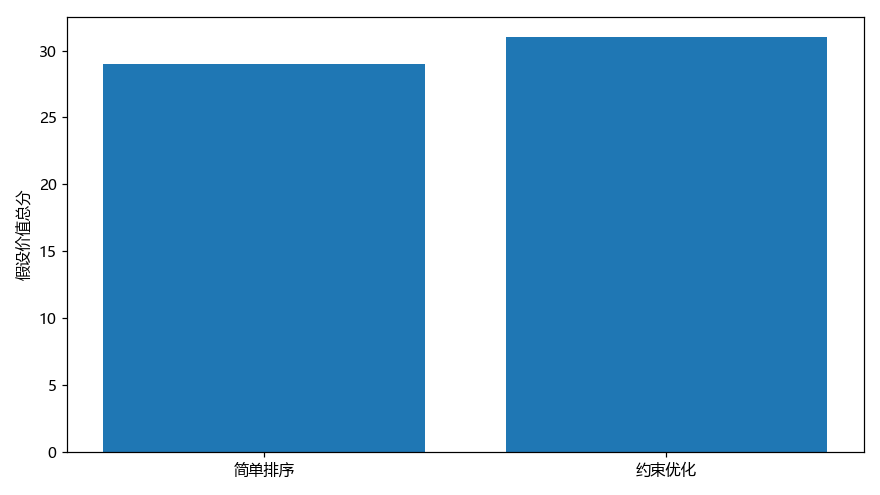

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
普通一维背包不处理任意任务依赖。所有成本和时间使用整数单位。UNKNOWN表示尚未确定，不等于INFEASIBLE；评分是显式假设。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。